In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn


In [3]:
a = np.ones(5)
print(a)

b = torch.from_numpy(a)
print(b)

a += 1

print(a)
print(b)
b.div_(2)
c = b.div(2)
print(c)
c = torch.rand(5)
print(b.device)
print(c.device)

[1. 1. 1. 1. 1.]
tensor([1., 1., 1., 1., 1.], dtype=torch.float64)
[2. 2. 2. 2. 2.]
tensor([2., 2., 2., 2., 2.], dtype=torch.float64)
tensor([0.5000, 0.5000, 0.5000, 0.5000, 0.5000], dtype=torch.float64)
cpu
cpu


In [4]:
weights = torch.ones(4, requires_grad=True)

for epoch in range(2):
    model_output = (weights*3).sum()
    model_output.backward()
    print(weights.grad)
    weights.grad.zero_()

tensor([3., 3., 3., 3.])
tensor([3., 3., 3., 3.])


In [5]:
x = torch.tensor(1.0)
y = torch.tensor(2.0)

w = torch.tensor(1.0, requires_grad=True)

# forward pass
y_hat = w*x
loss = (y_hat - y).pow(2).sum()

print(loss)

# backward pass
loss.backward()
print(w.grad)

tensor(1., grad_fn=<SumBackward0>)
tensor(-2.)


In [6]:
# f = w * x

# f = 2 * w

X = np.array([1, 2, 3, 4], dtype=np.float32)
Y = np.array([2, 4, 6, 8], dtype=np.float32)

w = 0.0

def forward(x):
    return w*x

def loss(y, y_hat):
    return ((y_hat - y)**2).mean()

# MSE = 1/N * (w*x - y)**2
# dl/dw = (2*x)/N * (w*x - y)

def gradient(x, y, y_hat):
    return np.dot(2*x, y_hat-y).mean()

print(f'Prediction before training: f(5) = {forward(5):.3f}')

learning_rate = 0.01
n_iters = 100

for epoch in range(n_iters):
    y_hat = forward(X)
    l = loss(Y, y_hat)
    dw = gradient(X, Y, y_hat)

    w -= learning_rate * dw

    if epoch % 10 == 0:
        print(f'epoch {epoch+1}: w = {w:.3f}, loss = {l:.8f}')


print(f'Prediction after training: f(5) = {forward(5):.3f}')

Prediction before training: f(5) = 0.000
epoch 1: w = 1.200, loss = 30.00000000
epoch 11: w = 2.000, loss = 0.00000033
epoch 21: w = 2.000, loss = 0.00000000
epoch 31: w = 2.000, loss = 0.00000000
epoch 41: w = 2.000, loss = 0.00000000
epoch 51: w = 2.000, loss = 0.00000000
epoch 61: w = 2.000, loss = 0.00000000
epoch 71: w = 2.000, loss = 0.00000000
epoch 81: w = 2.000, loss = 0.00000000
epoch 91: w = 2.000, loss = 0.00000000
Prediction after training: f(5) = 10.000


In [7]:
device = "cpu"
X = torch.tensor([1, 2, 3, 4], dtype=torch.float32)
Y = torch.tensor([2, 4, 6, 8], dtype=torch.float32)

w = torch.tensor(0.0, dtype=torch.float32, requires_grad=True)


def forward(x):
    return w * x

def loss(y, y_hat):
    return ((y_hat - y) ** 2).mean()


print(f'Prediction before training: f(5) = {forward(5):.3f}')

learning_rate = 0.01
n_iters = 100

for epoch in range(n_iters):
    y_hat = forward(X)
    l = loss(Y, y_hat)
    l.backward() # dl/dw


    with torch.no_grad():
        w -= learning_rate * w.grad

    w.grad.zero_()

    if epoch % 10 == 0:
        print(f'epoch {epoch + 1}: w = {w:.3f}, loss = {l:.8f}')

print(f'Prediction after training: f(5) = {forward(5):.3f}')

Prediction before training: f(5) = 0.000
epoch 1: w = 0.300, loss = 30.00000000
epoch 11: w = 1.665, loss = 1.16278565
epoch 21: w = 1.934, loss = 0.04506890
epoch 31: w = 1.987, loss = 0.00174685
epoch 41: w = 1.997, loss = 0.00006770
epoch 51: w = 1.999, loss = 0.00000262
epoch 61: w = 2.000, loss = 0.00000010
epoch 71: w = 2.000, loss = 0.00000000
epoch 81: w = 2.000, loss = 0.00000000
epoch 91: w = 2.000, loss = 0.00000000
Prediction after training: f(5) = 10.000


In [8]:

X = torch.tensor([[1], [2], [3], [4]], dtype=torch.float32)
Y = torch.tensor([[2], [4], [6], [8]], dtype=torch.float32)

X_test = torch.tensor([5], dtype=torch.float32)

n_samples, n_features = X.shape

input_size = n_features
output_size = n_features
#model = nn.Linear(in_features=input_size, out_features=output_size)

class LinearRegression(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.lin = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        return self.lin(x)

model = LinearRegression(input_size, output_size)

print(f'Prediction before training: f(5) = {model(X_test).item():.3f}')

learning_rate = 0.05
n_iters = 100

loss = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

for epoch in range(n_iters):
    y_hat = model(X)
    l = loss(Y, y_hat)
    l.backward()  # dl/dw

    optimizer.step()

    optimizer.zero_grad()

    if epoch % 10 == 0:
        [w, b] = model.parameters()
        print(f'epoch {epoch + 1}: w = {w[0][0].item():.3f}, loss = {l:.8f}')

print(f'Prediction after training: f(5) = {model(X_test).item():.3f}')

Prediction before training: f(5) = 3.266
epoch 1: w = 1.622, loss = 13.23513985
epoch 11: w = 1.843, loss = 0.03651451
epoch 21: w = 1.865, loss = 0.02700593
epoch 31: w = 1.884, loss = 0.01997340
epoch 41: w = 1.900, loss = 0.01477224
epoch 51: w = 1.914, loss = 0.01092545
epoch 61: w = 1.926, loss = 0.00808040
epoch 71: w = 1.937, loss = 0.00597622
epoch 81: w = 1.945, loss = 0.00441997
epoch 91: w = 1.953, loss = 0.00326899
Prediction after training: f(5) = 9.916


epoch: 10, loss = 1662.1606
epoch: 20, loss = 1282.2136
epoch: 30, loss = 1010.2470
epoch: 40, loss = 815.2280
epoch: 50, loss = 675.1555
epoch: 60, loss = 574.3945
epoch: 70, loss = 501.8103
epoch: 80, loss = 449.4551
epoch: 90, loss = 411.6464
epoch: 100, loss = 384.3125


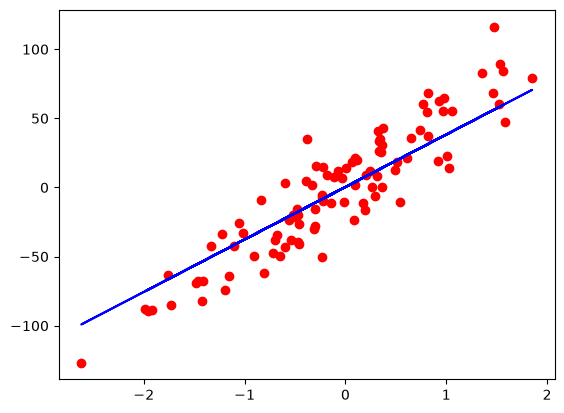

In [31]:
# 0) prepare data

X_numpy, y_numpy = datasets.make_regression(n_samples=100, n_features=1, noise=20, random_state=42)

X = torch.from_numpy(X_numpy.astype(np.float32))
y = torch.from_numpy(y_numpy.astype(np.float32))
y = y.view(y.shape[0], 1)

n_samples, n_features = X.shape

# 1) model
input_size = n_features
output_size = 1
model = nn.Linear(input_size, output_size)

# 2) loss and optimizer
learning_rate = 0.01
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

# 3) training loop
num_epochs = 100
for epoch in range(num_epochs):
    # forward pass
    y_hat = model(X)
    loss = criterion(y_hat, y)

    # backwards pass
    loss.backward()

    # update
    optimizer.step()
    optimizer.zero_grad()

    if (epoch + 1) % 10 == 0:
        print(f'epoch: {epoch + 1}, loss = {loss.item():.4f}')

# plot
predicted = model(X).detach().numpy()
plt.plot(X_numpy, y_numpy, 'ro')
plt.plot(X_numpy, predicted, 'b')
plt.show()


In [ ]:
# 0) prepare data
bc = datasets.load_breast_cancer()
X, y = bc.data, bc.target

n_samples, n_features = X.shape

print(n_samples, n_features)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# scale
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

X_train = torch.from_numpy(X_train.as_type(np.float32))
X_test = torch.from_numpy(X_test.as_type(np.float32))
y_train = torch.from_numpy(y_train.as_type(np.float32))
y_test = torch.from_numpy(y_test.as_type(np.float32))

y_train = y_train.view(y_train.shape[0], 1)
y_test = y_test.view(y_test.shape[0], 1)
# 1) model
# 2) loss and optimizer
# 3) training loop

569 30
